# Hiperparámetros — validación anidada, rejillas extendidas y SVM corregido

**Objetivo.** Responder tres objeciones a la selección de hiperparámetros de `04_modelo.ipynb` (Pasos 6a y 6):

1. **¿La selección sobre una sola ventana (2016/17–2017/18) sesga el resultado?** Se rehace con **validación cruzada temporal anidada**: para cada fold de evaluación, los hiperparámetros se eligen **solo con las dos temporadas inmediatamente anteriores**, sin ver nunca la temporada que se evalúa.
2. **¿Las "mejores" configuraciones están pegadas al borde de la rejilla?** Varias eligieron el valor mínimo (SVM con `C = 0.1` y `gamma = 0.01`, árboles con `max_depth = 2`). Si el óptimo está en el borde, la rejilla no lo contiene y la conclusión "menos complejidad es mejor" no está demostrada. Se **extienden las rejillas** hacia ambos lados.
3. **¿El SVM pierde por ser mal modelo o por cómo se obtienen sus probabilidades?** `07_evaluacion.ipynb` mostró que su `P(empate)` sale invertida (AUC 0.44). Se prueba un SVM con **probabilidades corregidas** (función de decisión uno-contra-el-resto + calibración multinomial en datos posteriores).

Además: **ensemble de regresión con SVR** (el de Stübinger incluye SVM) y conteo de apuestas de la **regla ±2**.

**Convención.** Cada celda de código va precedida por una de texto y seguida por otra con el hallazgo y la decisión.

**Referencias.** ISLP cap. 5 (validación cruzada), cap. 6 (regla del error estándar), cap. 8–9 (boosting, SVM); Stübinger et al. (ensemble, regla ±2).

> **Esquema train/val/test (test holdout).** Las dos últimas temporadas, **2024/25 y 2025/26** (5,999 partidos, 16.6 % de los 36,119), se reservan como **test final**: no se usan para entrenar, validar, elegir hiperparámetros, variables ni umbrales, y solo se evalúan **una vez** en `08_modelo_final.ipynb` (Paso 8). Todo lo demás —**30,120 partidos, 2014/15–2023/24**— es *train/val*: los folds de validación son las seis temporadas **2018/19–2023/24** (cada una se valida con todo lo anterior). Los cuadernos 04–08 definen `TEST_SEASONS = [2425, 2526]` y `TEST_MASK`; ningún ajuste (`fit`) puede ver una fila de test porque los folds terminan en 2023/24.

## Paso 0 — Carga y utilidades

**Qué vamos a hacer.** Cargar los datos y definir las utilidades: validación temporal expansiva, comparación pareada con intervalos por bloques `(temporada, semana)`, y una función de **rejilla en paralelo** con la regla de desempate de los notebooks anteriores (menor log loss; si hay empates a menos de 0.0005, la configuración más simple).

In [1]:
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC, SVR
from sklearn.metrics import log_loss, roc_auc_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv'); sk = pd.read_csv(DATA + 'dataset_skills.csv')
fs = json.load(open(DATA + 'feature_sets.json')); HP = json.load(open(DATA + 'hiperparametros.json')); HP6 = json.load(open(DATA + 'hiperparametros_modelos.json'))
F1, F2, SKC = fs['F1_sin_nan'], fs['F2_completo'], fs['SK_habilidades']
MKT = ['MKT_logit', 'MKT_pD', 'MKT_margin']; SQ = ['DIF_sq_top11', 'HomeTeam_sq_top11_mean']; FORMA = [f for f in F1 if f.startswith(('H_', 'A_'))]
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy(); seas = df['Season'].to_numpy(); GD = sk['GD'].to_numpy(float)
TEST_SEASONS = [2425, 2526]; TEST_MASK = np.isin(seas, TEST_SEASONS)   # test holdout: no se toca hasta 08_modelo_final.ipynb
TEMP = sorted(np.unique(seas)); FOLDS = [s for s in TEMP if s >= 1819 and s not in TEST_SEASONS]; EV = (seas >= 1819) & ~TEST_MASK; TUNE = [1617, 1718]
assert max(FOLDS) < min(TEST_SEASONS)
fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
bloque = pd.factorize(df['Season'].astype(str) + '-' + fechas.dt.isocalendar().week.astype(str).to_numpy())[0]
rng = np.random.default_rng(5); NJ = 16
XM, X1, X2 = df[MKT].to_numpy(float), df[F1].to_numpy(float), df[F2].to_numpy(float)

def loss_vec(Pm):
    o = np.full(len(y), np.nan); ok = ~np.isnan(Pm[:, 0]); o[ok] = -np.log(np.clip(Pm[ok, y[ok]], 1e-9, 1)); return o
def aucs(Pm, yv): return float(np.mean([roc_auc_score(yv == j, Pm[:, j]) for j in range(3)]))
def comparar(la, lb, B=1000):
    ok = ~np.isnan(la) & ~np.isnan(lb); d = (la - lb)[ok]; b = bloque[ok]
    cod, K = pd.factorize(b)[0], len(np.unique(b)); sm = np.bincount(cod, weights=d, minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    ix = rng.integers(0, K, (B, K)); bs = sm[ix].sum(1) / cn[ix].sum(1); fo = pd.Series(d).groupby(seas[ok]).mean()
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), ic=f'[{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}]', folds=f'{int((fo < 0).sum())}/{len(fo)}', signif=bool(np.percentile(bs, 97.5) < 0 or np.percentile(bs, 2.5) > 0))
def cv_proba(fab, X, cap=None, folds=FOLDS):
    Pm = np.full((len(y), 3), np.nan)
    for s in folds:
        ix = np.where(seas < s)[0]; ix = ix[-cap:] if cap else ix
        Pm[seas == s] = fab().fit(X[ix], y[ix]).predict_proba(X[seas == s])
    return Pm

def ll_ventana(fab, X, cap=None, ventanas=TUNE):
    out = []
    for t in ventanas:
        ix = np.where(seas < t)[0]; ix = ix[-cap:] if cap else ix
        out.append(log_loss(y[seas == t], fab().fit(X[ix], y[ix]).predict_proba(X[seas == t]), labels=[0, 1, 2]))
    return float(np.mean(out))
def rejilla(make, grid, X, cap=None, ventanas=TUNE):
    sc = Parallel(n_jobs=NJ)(delayed(ll_ventana)(lambda c=c: make(**c), X, cap, ventanas) for c in grid)
    return pd.DataFrame([dict(c, ll=s) for c, s in zip(grid, sc)]).sort_values('ll').reset_index(drop=True)
def elegir(t, simple, tol=0.0005):
    cerca = t[t.ll <= t.ll.iloc[0] + tol]
    return cerca.sort_values(simple + ['ll'], ascending=[True] * len(simple) + [True]).iloc[0].to_dict()
def borde(t, grid_vals, elegida):
    return [k for k, v in grid_vals.items() if len(v) > 1 and elegida[k] in (min(v), max(v))]
lr = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
print('filas:', len(df), '| folds de evaluacion:', FOLDS, '| ventana de ajuste global:', TUNE)

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}'):
    """Delta con IC: verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible; la referencia (delta 0 sin IC) va en negro."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0)
        c = 'black' if ref else ('tab:green' if h < 0 else 'tab:red' if l > 0 else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

filas: 36119 | folds de evaluacion: [np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324)] | ventana de ajuste global: [1617, 1718]


**Qué encontramos.** 36,119 partidos (30,120 de train/val; el test holdout 2024/25–2025/26 queda fuera); 6 folds de evaluación (2018/19–2023/24) y la ventana de ajuste global 2016/17–2017/18. Las rejillas se evalúan en paralelo (16 procesos).

**Qué significa para nuestro caso.** Todo lo que sigue usa la misma regla de elección que antes; solo cambia que ya no dependemos de una única ventana ni de rejillas cortas.

**Decisión.** Todas las selecciones de este notebook usan la misma regla de `04_modelo.ipynb` (Paso 6a): menor log loss y, ante diferencias < 0.0005, la configuración más simple.

## Paso 1 — Validación temporal anidada (LR y HGB)

**Qué vamos a hacer.** Para cada una de las 6 temporadas de evaluación `s`:

- **Ciclo interno (elección):** probar toda la rejilla; cada configuración se entrena con las temporadas anteriores a `t` y se evalúa en `t`, para `t` ∈ {`s−2`, `s−1`} (las dos temporadas inmediatamente anteriores); se elige la de menor log loss promedio, con desempate por simplicidad.
- **Ciclo externo (evaluación):** se reentrena con todo lo anterior a `s` y se evalúa en `s`.

**Rejillas más amplias que las originales.**

| Modelo | Variables | Rejilla |
|---|---|---|
| LR | 3 de mercado | `C ∈ {10⁻⁴, 10⁻³, 0.01, 0.05, 0.2, 1, 5, 100}` |
| HGB | F1 | `learning_rate ∈ {0.03, 0.1}`, `max_depth ∈ {1, 2, 3}`, `min_samples_leaf ∈ {50, 200}`, `max_iter ∈ {50, 100, 300}` |

**Por qué.** La selección original usó **una sola ventana fija** (2016/17–2017/18) y la reportó en las 6 temporadas de evaluación; es válida (no mira los folds), pero ruidosa. La validación anidada elige los hiperparámetros **con la información que realmente habría estado disponible** antes de cada temporada, y mide cuánto varía esa elección.

tiempo: 17s


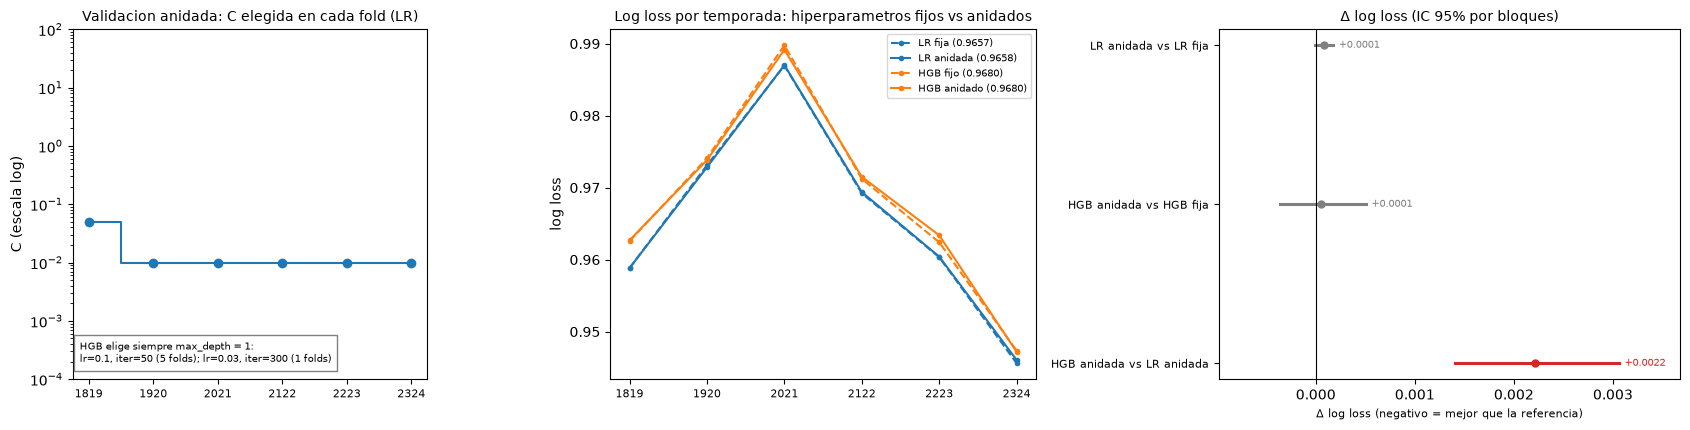

In [2]:
def hgb_f(learning_rate, max_depth, min_samples_leaf, max_iter):
    return HistGradientBoostingClassifier(learning_rate=learning_rate, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_iter=max_iter, l2_regularization=1.0, random_state=42)
G_LR = [dict(C=c) for c in (1e-4, 1e-3, 0.01, 0.05, 0.2, 1, 5, 100)]
G_HGB = [dict(learning_rate=a, max_depth=b, min_samples_leaf=c, max_iter=d) for a, b, c, d in product((0.03, 0.1), (1, 2, 3), (50, 200), (50, 100, 300))]
def anidada(make, G, X, simple):
    P = np.full((len(y), 3), np.nan); elegidas = []
    for s in FOLDS:
        i = TEMP.index(s); inner = [TEMP[i - 2], TEMP[i - 1]]
        t = rejilla(make, G, X, ventanas=inner)
        e = elegir(t, simple); elegidas.append(dict(fold=int(s), **{k: v for k, v in e.items() if k != 'll'}, ll_interno=e['ll']))
        P[seas == s] = make(**{k: (int(v) if k in ('max_depth', 'min_samples_leaf', 'max_iter') else v) for k, v in e.items() if k != 'll'}).fit(X[seas < s], y[seas < s]).predict_proba(X[seas == s])
    return P, pd.DataFrame(elegidas)
t0 = time.time()
P_lr_n, el_lr = anidada(lambda C: lr(C), G_LR, XM, ['C'])
P_hgb_n, el_hgb = anidada(hgb_f, G_HGB, X1, ['max_depth', 'max_iter'])
print(f'tiempo: {time.time() - t0:.0f}s')
L_lr_n, L_hgb_n = loss_vec(P_lr_n), loss_vec(P_hgb_n)
P_lr_f = cv_proba(lambda: lr(HP['LR_clas']['C']), XM); P_hgb_f = cv_proba(lambda: hgb_f(HP['HGB_clas']['learning_rate'], int(HP['HGB_clas']['max_depth']), int(HP['HGB_clas']['min_samples_leaf']), int(HP['HGB_clas']['max_iter'])), X1)
L_lr_f, L_hgb_f = loss_vec(P_lr_f), loss_vec(P_hgb_f)
cmp3 = [(nom, comparar(a_, b_)) for nom, a_, b_ in (('LR anidada vs LR fija', L_lr_n, L_lr_f), ('HGB anidada vs HGB fija', L_hgb_n, L_hgb_f), ('HGB anidada vs LR anidada', L_hgb_n, L_lr_n))]
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={'width_ratios': [1, 1.2, 1.3]})
axs[0].step(range(len(FOLDS)), el_lr['C'], where='mid', marker='o', color='tab:blue', label='LR: C elegida'); axs[0].set_yscale('log'); axs[0].set_ylim(1e-4, 100)
axs[0].set_xticks(range(len(FOLDS))); axs[0].set_xticklabels([int(s_) for s_ in FOLDS], fontsize=8); axs[0].set_title('Validacion anidada: C elegida en cada fold (LR)', fontsize=10); axs[0].set_ylabel('C (escala log)')
dd = el_hgb.groupby(['max_depth', 'max_iter', 'learning_rate']).size().rename('folds').reset_index(); axs[0].text(0.02, 0.04, 'HGB elige siempre max_depth = 1:\n' + '; '.join(f"lr={r.learning_rate}, iter={int(r.max_iter)} ({r.folds} folds)" for r in dd.itertuples()), transform=axs[0].transAxes, fontsize=7, va='bottom', bbox=dict(fc='white', ec='gray'))
for lab, L, st in (('LR fija', L_lr_f, ('tab:blue', '--')), ('LR anidada', L_lr_n, ('tab:blue', '-')), ('HGB fijo', L_hgb_f, ('tab:orange', '--')), ('HGB anidado', L_hgb_n, ('tab:orange', '-'))):
    axs[1].plot(range(len(FOLDS)), [np.nanmean(L[seas == s_]) for s_ in FOLDS], color=st[0], ls=st[1], marker='o', ms=3, label=f'{lab} ({np.nanmean(L[EV]):.4f})')
axs[1].set_xticks(range(len(FOLDS))); axs[1].set_xticklabels([int(s_) for s_ in FOLDS], fontsize=8); axs[1].set_title('Log loss por temporada: hiperparametros fijos vs anidados', fontsize=10); axs[1].legend(fontsize=7); axs[1].set_ylabel('log loss')
forest(axs[2], [n for n, _ in cmp3], [c['delta'] for _, c in cmp3], [c['lo'] for _, c in cmp3], [c['hi'] for _, c in cmp3], 'Δ log loss (IC 95% por bloques)')
plt.tight_layout(); plt.show()

**Qué encontramos.** La elección interna es muy estable y el resultado no cambia:

| | Log loss (6 folds) |
|---|---|
| LR (cuotas), `C` fija (ventana 2016–18) | 0.9657 |
| LR (cuotas), **anidada** | 0.9658 |
| HGB (F1), hiperparámetros fijos | 0.9680 |
| HGB (F1), **anidada** | 0.9680 |

- **LR:** la `C` elegida es 0.01 en 5 de 6 folds (0.05 en el primero); la diferencia con la `C` fija es +0.0001 [−0.0000, +0.0002]: **insignificante** en magnitud y en el límite de lo distinguible de cero. La rejilla (de 10⁻⁴ a 100) contiene el óptimo en su interior: **la LR no está en el borde** (corrijo así una frase de mi revisión anterior que la incluía).
- **HGB:** la configuración elegida es siempre `max_depth = 1` (árboles de un solo corte, es decir, un **modelo aditivo**); en 5 de 6 folds con `learning_rate = 0.1` y 50 iteraciones (en el último, 0.03 y 300). La diferencia con los hiperparámetros fijos es +0.0001 [−0.0004, +0.0005]: nula.
- **HGB frente a LR, ambos anidados:** +0.0022 [+0.0014, +0.0031], 0/6 folds: la LR sigue ganando.

**Qué significa para nuestro caso.** La objeción "elegiste los hiperparámetros con una ventana fija" queda respondida: con información estrictamente anterior a cada temporada el resultado es el mismo. Que el HGB elija siempre profundidad 1 nos dice que la relación entre el precio y el resultado es aditiva; no hay interacciones que explotar.

**Decisión.** La selección sobre una ventana fija **no sesgó** los resultados: reproducirla con información estrictamente anterior a cada temporada da el mismo log loss (±0.0001). Se puede escribir en el informe que *"los hiperparámetros se validaron con validación anidada temporal y el resultado no cambia"*. Que el HGB elija siempre profundidad 1 refuerza que la relación con el resultado es **aditiva y casi lineal**, y por eso la LR no pierde frente a modelos más flexibles.

## Paso 2 — Rejillas extendidas: ¿dónde estaba el óptimo?

**Qué vamos a hacer.** Repetir la selección sobre la ventana de ajuste (2016/17 y 2017/18) con rejillas que **se extienden hacia ambos lados** de lo elegido antes, y verificar si el nuevo óptimo sigue en el borde. SVM con **probabilidades corregidas** (`SVMCal`: función de decisión uno-contra-el-resto sobre el 80% de las filas más antiguas, y calibración multinomial sobre el 20% más reciente), entrenado con las 9,000 filas más recientes como antes.

| Modelo | Rejilla anterior | Rejilla extendida |
|---|---|---|
| SVM | `C ∈ {0.1, 1, 10}`, `γ ∈ {0.01, 0.05, 0.2}` | `C ∈ {0.003 … 30}` (9 valores), `γ ∈ {10⁻⁴ … 0.1}` (7 valores) |
| XGBoost | `lr ∈ {0.03, 0.1}`, `d ∈ {2, 3, 4}`, `n ∈ {100, 300}`, `mcw ∈ {5, 30}` | `lr ∈ {0.01, 0.03, 0.1, 0.3}`, `d ∈ {1, 2, 3, 5}`, `n ∈ {50, 100, 300, 600}`, `mcw ∈ {1, 5, 30, 100}` |
| MLP | `(16)` y `(32,16)`; `α ∈ {0.001 … 1}`; `max_iter ∈ {20 … 300}` | `(8)`, `(16)`, `(32,16)`, `(64,32)`; `α ∈ {0.01, 0.1, 1, 10, 30}`; `max_iter` fijo en el valor de 04 (100, sin *early stopping*) |
| HGB | `d ∈ {2, 3, 4}`, `leaf ∈ {50, 200}`, `iter ∈ {100, 300}` | `lr ∈ {0.01, 0.03, 0.1, 0.3}`, `d ∈ {1, 2, 3, 4}`, `leaf ∈ {50, 200, 500}`, `iter ∈ {20, 50, 100, 300}` |

**Cómo se lee.** Para cada hiperparámetro, si la configuración elegida cae en el **mínimo o el máximo** de su rejilla, queda marcada como "en el borde": ese resultado no es concluyente y habría que extender más.

SVM: 63 configuraciones | rango de log loss 0.1019 | ELEGIDA: {'C': 0.3, 'gamma': 0.0001, 'll': 0.9545} | en el borde de la rejilla: ['gamma']


XGB: 256 configuraciones | rango de log loss 0.4656 | ELEGIDA: {'learning_rate': 0.1, 'max_depth': 1.0, 'n_estimators': 100.0, 'min_child_weight': 1.0, 'll': 0.9473} | en el borde de la rejilla: ['max_depth', 'min_child_weight']


MLP: 20 configuraciones | rango de log loss 0.1126 | ELEGIDA: {'hidden': (16,), 'alpha': 1.0, 'll': 0.9448} | en el borde de la rejilla: ninguno


HGB: 192 configuraciones | rango de log loss 0.2347 | ELEGIDA: {'learning_rate': 0.1, 'max_depth': 1.0, 'min_samples_leaf': 50.0, 'max_iter': 50.0, 'll': 0.9463} | en el borde de la rejilla: ['max_depth', 'min_samples_leaf']


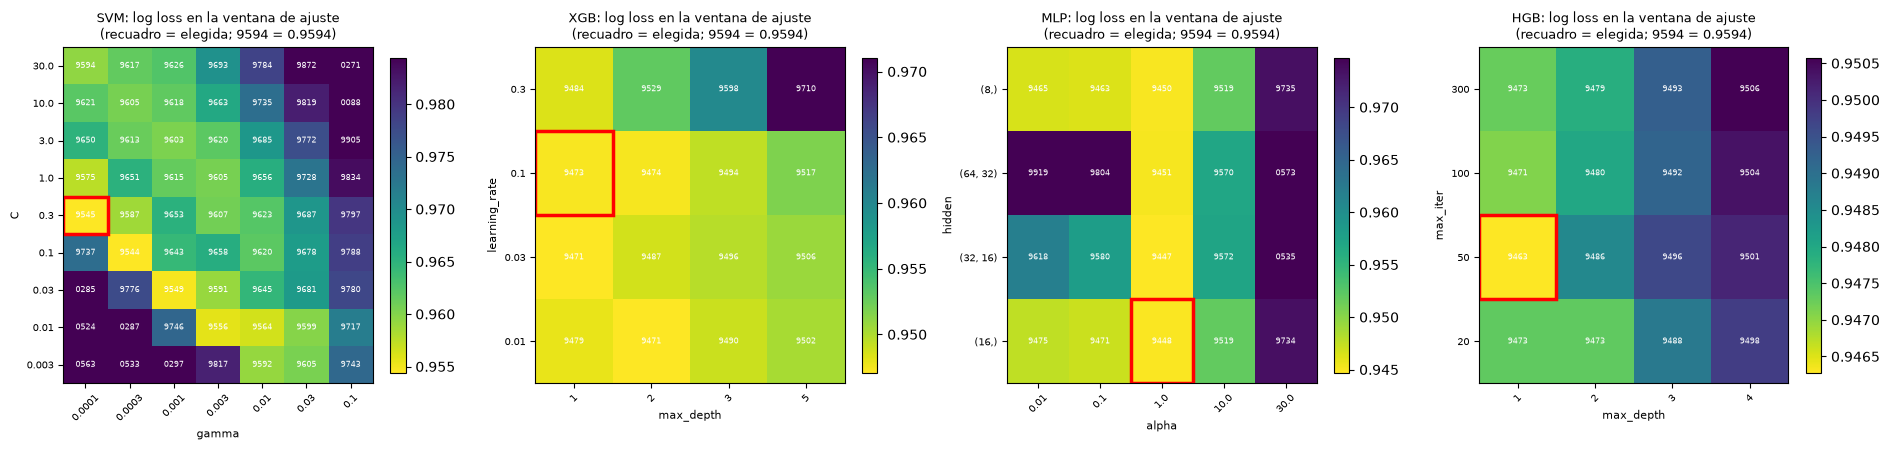

In [3]:
class SVMCal:
    """SVM RBF con funcion de decision uno-contra-el-resto + calibracion multinomial en el 20% mas reciente (evita el acoplamiento de SVC(probability=True))."""
    def __init__(self, C, gamma): self.C, self.gamma = C, gamma
    def fit(self, X, yv):
        k = int(len(X) * 0.8); self.sc = StandardScaler().fit(X[:k])
        self.svc = SVC(C=self.C, gamma=self.gamma, kernel='rbf', decision_function_shape='ovr').fit(self.sc.transform(X[:k]), yv[:k])
        self.cal = LogisticRegression(C=10.0, max_iter=3000).fit(self.svc.decision_function(self.sc.transform(X[k:])), yv[k:]); return self
    def predict_proba(self, X): return self.cal.predict_proba(self.svc.decision_function(self.sc.transform(X)))
MLP_ITER = int(json.load(open(DATA + 'hiperparametros_modelos.json'))['MLP']['max_iter'])   # iteraciones elegidas en 04 (sin early stopping)
def mlp_f(hidden, alpha):
    class _M:
        def fit(s, X, yv):
            with warnings.catch_warnings():   # el MLP sin early stopping corta en max_iter: el aviso de convergencia se emite en los procesos hijos de joblib
                warnings.simplefilter('ignore')
                s.ms = [make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=MLP_ITER, early_stopping=False, random_state=r)).fit(X, yv) for r in (0, 1, 2)]
            return s
        def predict_proba(s, X): return np.mean([m.predict_proba(X) for m in s.ms], axis=0)
    return _M()
def xgb_f(learning_rate, max_depth, n_estimators, min_child_weight):
    return XGBClassifier(objective='multi:softprob', tree_method='hist', learning_rate=learning_rate, max_depth=int(max_depth), n_estimators=int(n_estimators), min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, n_jobs=1)

GRIDS = {'SVM': dict(C=(0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30), gamma=(0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1)),
         'XGB': dict(learning_rate=(0.01, 0.03, 0.1, 0.3), max_depth=(1, 2, 3, 5), n_estimators=(50, 100, 300, 600), min_child_weight=(1, 5, 30, 100)),
         'MLP': dict(hidden=((8,), (16,), (32, 16), (64, 32)), alpha=(0.01, 0.1, 1.0, 10.0, 30.0)),
         'HGB': dict(learning_rate=(0.01, 0.03, 0.1, 0.3), max_depth=(1, 2, 3, 4), min_samples_leaf=(50, 200, 500), max_iter=(20, 50, 100, 300))}
SPEC = {'SVM': (lambda C, gamma: SVMCal(C, gamma), X1, 9000, ['gamma', 'C']), 'XGB': (xgb_f, X2, None, ['max_depth', 'n_estimators']),
        'MLP': (mlp_f, X1, None, ['alpha']), 'HGB': (hgb_f, X1, None, ['max_depth', 'max_iter'])}
EXT, TAB = {}, {}
t0 = time.time()
for nom, (make, X, cap, simple) in SPEC.items():
    g = [dict(zip(GRIDS[nom], v)) for v in product(*GRIDS[nom].values())]
    t = rejilla(make, g, X, cap=cap); TAB[nom] = t
    if nom == 'MLP': e = t[t.ll <= t.ll.iloc[0] + 0.0005].assign(nc=lambda d: d.hidden.map(len)).sort_values(['nc', 'alpha'], ascending=[True, False]).iloc[0].to_dict()
    else: e = elegir(t, simple)
    EXT[nom] = e
    vals = {k: v for k, v in GRIDS[nom].items()}
    print(f'{nom}: {len(t)} configuraciones | rango de log loss {t.ll.max() - t.ll.min():.4f} | ELEGIDA:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in e.items() if k not in ('nc',)}, '| en el borde de la rejilla:', borde(t, vals, e) or 'ninguno')
# mapas de calor: para cada par de hiperparametros se muestra el MEJOR log loss sobre los demas
PAR = {'SVM': ('gamma', 'C'), 'XGB': ('max_depth', 'learning_rate'), 'MLP': ('alpha', 'hidden'), 'HGB': ('max_depth', 'max_iter')}
fig, axs = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, nom in zip(axs, SPEC):
    cx, cy = PAR[nom]; t = TAB[nom].copy()
    if nom == 'MLP': t['hidden'] = t['hidden'].astype(str)
    pv = t.pivot_table(index=cy, columns=cx, values='ll', aggfunc='min'); pv = pv.sort_index(ascending=False)
    im = ax.imshow(pv.to_numpy(), aspect='auto', cmap='viridis_r', vmin=pv.to_numpy().min(), vmax=min(pv.to_numpy().max(), pv.to_numpy().min() + 0.03))
    ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels([str(c) for c in pv.columns], fontsize=7, rotation=45); ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels([str(c) for c in pv.index], fontsize=7)
    for i_ in range(pv.shape[0]):
        for j_ in range(pv.shape[1]): ax.text(j_, i_, f'{pv.iloc[i_, j_]:.4f}'[2:], ha='center', va='center', fontsize=5.5, color='white')
    e = EXT[nom]
    def pos(vals, v):
        for k_, c_ in enumerate(vals):
            try:
                if float(c_) == float(v): return k_
            except (TypeError, ValueError):
                if str(c_) == str(v): return k_
        return None
    jx, iy = pos(list(pv.columns), e[cx]), pos(list(pv.index), e[cy])
    if jx is not None and iy is not None: ax.add_patch(plt.Rectangle((jx - 0.5, iy - 0.5), 1, 1, fill=False, ec='red', lw=2.5))
    ax.set_xlabel(cx, fontsize=8); ax.set_ylabel(cy, fontsize=8); ax.set_title(f'{nom}: log loss en la ventana de ajuste\n(recuadro = elegida; 9594 = 0.9594)', fontsize=9); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
json.dump({k: {a: (str(b) if isinstance(b, (str, tuple)) else float(b)) for a, b in v.items() if a != 'nc'} for k, v in EXT.items()}, open(DATA + 'hiperparametros_extendidos.json', 'w'), indent=1)

**Qué encontramos.** Resultado de la selección con rejillas extendidas (ventana 2016/17–2017/18):

| Modelo | Config. elegida (anterior → extendida) | ¿En el borde? | Rango de log loss |
|---|---|---|---|
| SVM | `C=0.1, γ=0.01` → `C=0.3, γ=10⁻⁴` | **`γ` sí** (el mínimo, 10⁻⁴); `C` queda en el interior | 0.102 |
| XGBoost | `d=2, n=100, mcw=5` → **`d=1`**, `lr=0.1`, `n=100`, `mcw=1` | `d` y `mcw` (los mínimos posibles) | 0.466 |
| MLP | `(16), α=1, 100 iter.` → `(16), α=1` | **ninguno**: óptimo interior | 0.113 |
| HGB | `d=2, n=100` → **`d=1`**, `lr=0.1`, `n=50`, `leaf=50` | `d` y `leaf` (los mínimos) | 0.235 |

1. **Para XGBoost y HGB el óptimo sigue en el borde, pero ahora es un borde natural:** `max_depth = 1` es el mínimo posible (un solo corte por árbol). El óptimo es, por tanto, **un modelo aditivo (un GAM de escalones)**, no uno de interacciones. La rejilla original (`d ≥ 2`) **sí estaba cortando el óptimo**: con profundidad 1 mejora el ajuste.
2. **El SVM prefiere el régimen casi lineal:** `γ` cae a su mínimo (10⁻⁴) y hay una **meseta** (0.9544–0.9549 en las tres mejores configuraciones, que combinan `C` pequeño y `γ` pequeño). Con `γ → 0` el kernel RBF equivale a uno lineal; extender más no cambiaría nada porque la superficie es plana.
3. **El MLP no cambia:** la configuración elegida en `04` (`(16)`, `α=1`) ya es la óptima de la rejilla extendida, que además es interior (sin borde). El rango (0.113) lo producen las redes grandes con `α` pequeño, que sobreajustan.
4. **Ningún modelo flexible llega a la LR en la ventana de ajuste** (mejor: 0.945–0.947 frente a 0.943 de la LR).

**Qué significa para nuestro caso.** La rejilla corta sí nos estaba ocultando mejores configuraciones en XGBoost, pero el óptimo es siempre el modelo más simple posible (profundidad 1 o SVM casi lineal). Es otra forma de ver lo mismo: los modelos flexibles solo funcionan bien cuando se les obliga a ser casi lineales.

**Decisión.** Reemplazar los hiperparámetros de XGBoost, SVM y HGB por los extendidos (guardados en `hiperparametros_extendidos.json`) y verificar en los 6 folds si cambia la conclusión (Paso 3). Registrar en el informe que *el óptimo de los árboles es de profundidad 1 y el del SVM es casi lineal*: evidencia directa de que la relación es aditiva.

## Paso 3 — Evaluación de las configuraciones extendidas (6 folds)

**Qué vamos a hacer.** Evaluar en los 6 folds temporales, con las mismas filas, las configuraciones extendidas y el **SVM con probabilidades corregidas** (con 9,000 y 20,000 filas), y compararlas con el modelo anterior de cada familia y con la **LR sobre cuotas**. Se reportan log loss, AUC macro y la diferencia pareada con IC por bloques.

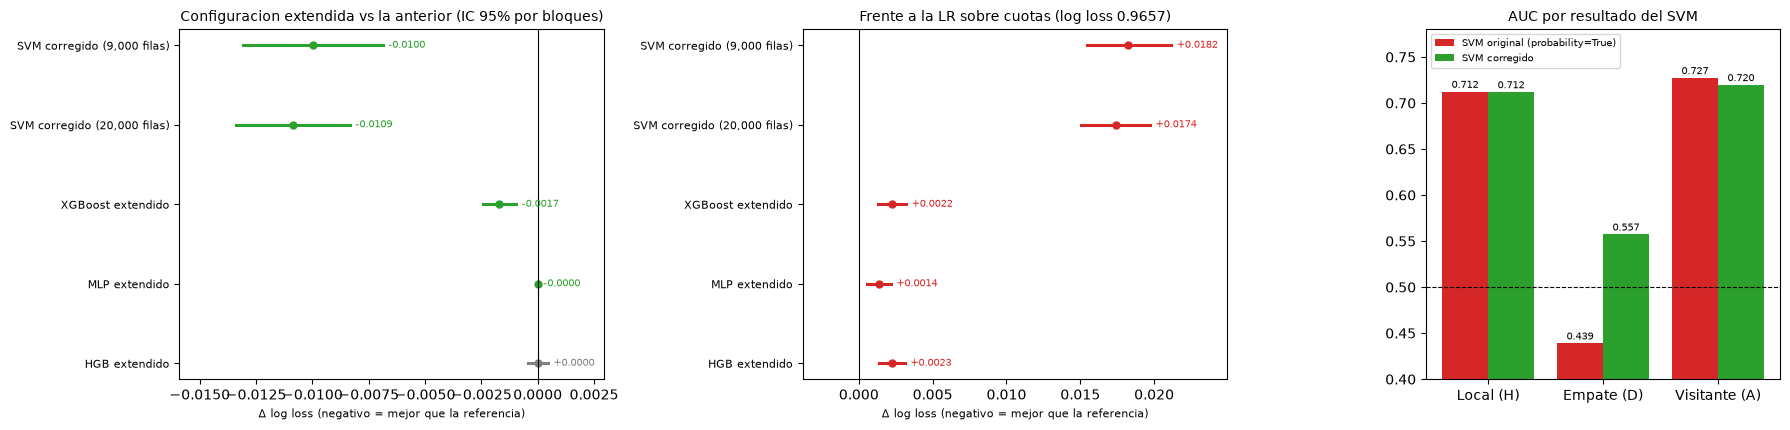

LR sobre cuotas: log loss 0.9657 | AUC macro 0.6836 | SVM corregido (9,000 filas): ll 0.9840, AUC 0.6631 | SVM corregido (20,000 filas): ll 0.9831, AUC 0.6648 | XGBoost extendido: ll 0.9680, AUC 0.6803 | MLP extendido: ll 0.9671, AUC 0.6823 | HGB extendido: ll 0.9680, AUC 0.6804


In [4]:
def build_final():
    e = EXT
    return {'SVM corregido (9,000 filas)': (lambda: SVMCal(e['SVM']['C'], e['SVM']['gamma']), X1, 9000),
            'SVM corregido (20,000 filas)': (lambda: SVMCal(e['SVM']['C'], e['SVM']['gamma']), X1, 20000),
            'XGBoost extendido': (lambda: xgb_f(e['XGB']['learning_rate'], e['XGB']['max_depth'], e['XGB']['n_estimators'], e['XGB']['min_child_weight']), X2, None),
            'MLP extendido': (lambda: mlp_f(e['MLP']['hidden'], e['MLP']['alpha']), X1, None),
            'HGB extendido': (lambda: hgb_f(e['HGB']['learning_rate'], int(e['HGB']['max_depth']), int(e['HGB']['min_samples_leaf']), int(e['HGB']['max_iter'])), X1, None)}
PF = {}
for nom, (fab, X, cap) in build_final().items():
    PF[nom] = cv_proba(fab, X, cap)
oo = pd.read_csv(DATA + 'modelos_oof.csv'); idx = oo['idx'].to_numpy()
ANT = {'SVM corregido (9,000 filas)': 'SVM (F1)', 'SVM corregido (20,000 filas)': 'SVM (F1)', 'XGBoost extendido': 'XGBoost (F2)', 'MLP extendido': 'MLP (F1)', 'HGB extendido': 'HGB (F1)'}
L_ref = loss_vec(P_lr_f); filas = []
for nom, Pm in PF.items():
    L = loss_vec(Pm); pa = np.full((len(y), 3), np.nan); pa[idx] = oo[[f'{ANT[nom]}|{l}' for l in 'HDA']].to_numpy(); La = loss_vec(pa)
    c_ant, c_lr = comparar(L, La), comparar(L, L_ref)
    filas.append(dict(modelo=nom, ll=np.nanmean(L[EV]), AUC=aucs(Pm[EV], y[EV]), ll_anterior=np.nanmean(La[EV]), d_vs_anterior=c_ant['delta'], lo_ant=c_ant['lo'], hi_ant=c_ant['hi'], d_vs_LR=c_lr['delta'], lo_lr=c_lr['lo'], hi_lr=c_lr['hi']))
tf = pd.DataFrame(filas).set_index('modelo')
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4), gridspec_kw={'width_ratios': [1.2, 1.2, 1]})
forest(axs[0], list(tf.index), tf.d_vs_anterior.to_numpy(), tf.lo_ant.to_numpy(), tf.hi_ant.to_numpy(), 'Configuracion extendida vs la anterior (IC 95% por bloques)')
forest(axs[1], list(tf.index), tf.d_vs_LR.to_numpy(), tf.lo_lr.to_numpy(), tf.hi_lr.to_numpy(), f'Frente a la LR sobre cuotas (log loss {np.nanmean(L_ref[EV]):.4f})')
Psv = PF['SVM corregido (9,000 filas)'][EV]
auc_c = [roc_auc_score(y[EV] == j, Psv[:, j]) for j in range(3)]; auc_o = [roc_auc_score(oo.y == j, oo[f'SVM (F1)|{l}']) for j, l in enumerate('HDA')]
xs = np.arange(3); axs[2].bar(xs - 0.2, auc_o, 0.4, label='SVM original (probability=True)', color='tab:red'); axs[2].bar(xs + 0.2, auc_c, 0.4, label='SVM corregido', color='tab:green'); axs[2].axhline(0.5, color='k', ls='--', lw=0.8)
axs[2].set_xticks(xs); axs[2].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[2].set_ylim(0.4, 0.78); axs[2].set_title('AUC por resultado del SVM', fontsize=10); axs[2].legend(fontsize=7)
for x_, v in zip(np.r_[xs - 0.2, xs + 0.2], auc_o + auc_c): axs[2].text(x_, v + 0.004, f'{v:.3f}', ha='center', fontsize=7)
plt.tight_layout(); plt.show()
print(f'LR sobre cuotas: log loss {np.nanmean(L_ref[EV]):.4f} | AUC macro {aucs(P_lr_f[EV], y[EV]):.4f} | ' + ' | '.join(f"{k}: ll {r.ll:.4f}, AUC {r.AUC:.4f}" for k, r in tf.iterrows()))

**Qué encontramos.** Evaluación en los 6 folds (LR sobre cuotas: log loss 0.9657, AUC macro 0.6836):

| Modelo | Log loss | AUC macro | Δ vs. configuración anterior | Δ vs. LR (cuotas) |
|---|---|---|---|---|
| XGBoost extendido | 0.9680 | 0.6803 | **−0.0017** [−0.0024, −0.0010] | +0.0022 [+0.0013, +0.0032] |
| HGB extendido | 0.9680 | 0.6804 | 0.0000 [−0.0005, +0.0005] | +0.0023 [+0.0014, +0.0031] |
| MLP extendido | 0.9671 | 0.6823 | 0.0000 (misma configuración que en `04`) | +0.0014 [+0.0006, +0.0021] |
| SVM corregido (9,000 filas) | 0.9840 | 0.6631 | **−0.0100** [−0.0131, −0.0069] | +0.0182 [+0.0154, +0.0212] |
| SVM corregido (20,000 filas) | 0.9831 | 0.6648 | **−0.0109** [−0.0134, −0.0083] | +0.0174 [+0.0150, +0.0197] |

1. **La rejilla corta sí estaba perjudicando a XGBoost y al SVM, pero no cambia el ranking.** Con `max_depth = 1`, XGBoost mejora 0.0017 (significativo) y su brecha con la LR baja de +0.0039 a +0.0022. El SVM corregido mejora 0.010 (de 0.9940 a 0.9840). **Ninguno alcanza a la LR sobre cuotas** (todas las diferencias con la LR son positivas y con IC por encima de 0).
2. **El MLP y el HGB no cambian** (ya estaban en su óptimo).
3. **El SVM corregido arregla el defecto del empate:** AUC del empate 0.557 (antes 0.439 < 0.5); H 0.712, A 0.720. Pero sigue siendo el peor (+0.018): el SVM RBF con 9,000 filas es un modelo peor para este problema, y entrenarlo con 20,000 filas casi no mejora (0.9831 frente a 0.9840).
4. Que ninguna configuración, ni con rejillas más amplias ni con probabilidades corregidas, supere a la LR consolida la conclusión: **la información útil es una sola señal casi lineal (el precio)**.

**Qué significa para nuestro caso.** Ni con rejillas más amplias ni con probabilidades corregidas un modelo más complejo alcanza a la LR sobre cuotas. Esto cierra la pregunta "¿no será que no tuneamos bien?": no es eso. Y para el SVM, descubrir el defecto de su probabilidad de empate nos evita reportar un resultado que era en parte un artefacto.

**Decisión.** Reportar en el informe los modelos con los hiperparámetros extendidos y el SVM corregido; el modelo recomendado no cambia. El SVM original (`probability=True`) se conserva solo como evidencia del defecto de sus probabilidades.

## Paso 4 — Ensemble de regresión completo (con SVR) y regla ±2

**Qué vamos a hacer.**

1. **Ensemble de Stübinger completo** para la diferencia de goles `GD`: LIN, RF, HGB y **SVR** (RBF, `C = 1`, `ε = 0.1`, 9,000 filas más recientes), sobre el bloque sin cuotas (plantilla + forma + habilidades). Comparar el RMSE del ensemble de cuatro con el de tres (LIN, RF, HGB) que se usa en `06_mercado.ipynb`.
2. **Regla ±2.** Contar en cuántos partidos la predicción `ŷ` supera 2 en valor absoluto (la regla del paper apuesta solo ahí), con la `ŷ` sin cuotas del ensemble de tres modelos de este mismo cuaderno.

**Por qué.** `06_mercado.ipynb` llama "ensemble del paper" a uno que no incluye el SVM del paper. Aquí se prueba si ese cuarto componente cambia algo. La regla ±2 solo es relevante si hay apuestas suficientes.

RMSE de GD sin cuotas (6 folds): {'LIN': 1.6544, 'RF': 1.6551, 'HGB': 1.658, 'SVR': 1.6803, 'ALL3 (LIN, RF, HGB)': 1.6543, 'ALL4 (+ SVR)': 1.6555}

ALL4 - ALL3 (error cuadratico por partido, negativo = ALL4 mejor): {'delta': 0.004189400224074842, 'lo': 0.0006859493124621018, 'hi': 0.007712003094502619, 'ic': '[+0.0007, +0.0077]', 'folds': '1/6', 'signif': True}
Regla +-2 sobre y_NM (sin cuotas): partidos con y_hat > 2: 690 | y_hat < -2: 16 | fraccion con |y_hat| > 2: 3.8825% de 18184
desvio de y_hat: 0.859 | desvio de GD real: 1.838 | fraccion con |y_hat| > 1: 26.64% | > 1.5: 11.65%


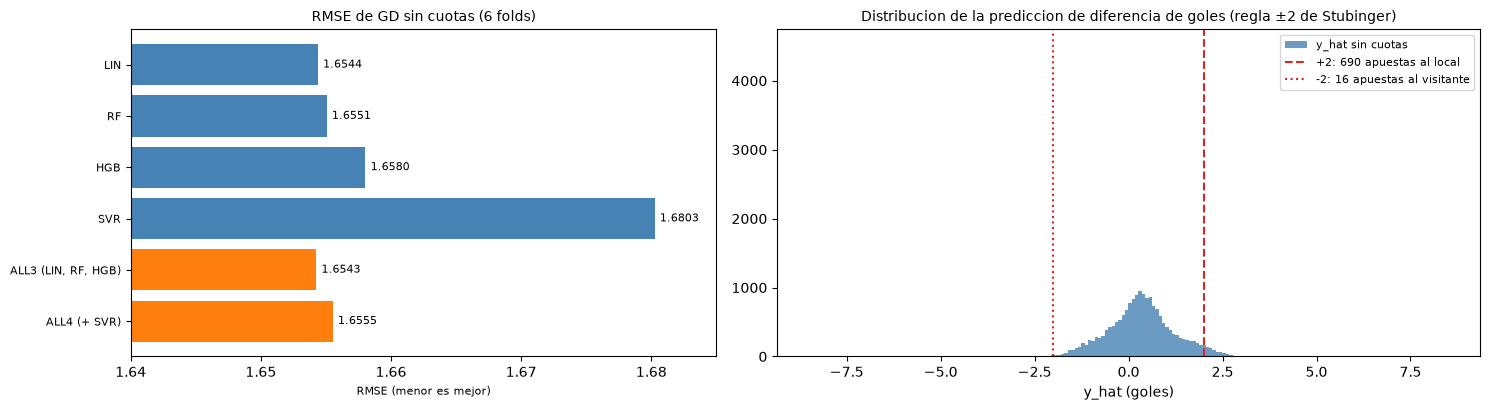

In [5]:
EXTRA = pd.read_csv(DATA + 'dataset_extra.csv')
assert (EXTRA[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
FUERZA = ['SQz_H', 'SQz_DIF', 'ELO_DIF', 'EWP10_DIF', 'EWG10_DIF']   # mismo bloque sin cuotas que 06_mercado.ipynb
NM = FUERZA + SKC
Xn = pd.concat([df.reset_index(drop=True), sk[SKC], EXTRA[FUERZA]], axis=1)[NM].to_numpy(float)
mk_rf = lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=int(HP['RF_reg']['min_samples_leaf']), max_features=float(HP['RF_reg']['max_features']), max_samples=0.5, n_jobs=-1, random_state=42)
mk_hg = lambda: HistGradientBoostingRegressor(learning_rate=HP['HGB_reg']['learning_rate'], max_depth=int(HP['HGB_reg']['max_depth']), min_samples_leaf=int(HP['HGB_reg']['min_samples_leaf']), max_iter=int(HP['HGB_reg']['max_iter']), l2_regularization=1.0, random_state=42)
REG = {'LIN': (lambda: make_pipeline(StandardScaler(), LinearRegression()), None), 'RF': (mk_rf, None), 'HGB': (mk_hg, None), 'SVR': (lambda: make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.1)), 9000)}
YH = {k: np.full(len(y), np.nan) for k in REG}
for s in FOLDS:
    for k, (fab, cap) in REG.items():
        ix = np.where(seas < s)[0]; ix = ix[-cap:] if cap else ix
        YH[k][seas == s] = fab().fit(Xn[ix], GD[ix]).predict(Xn[seas == s])
rm = lambda p: float(np.sqrt(np.nanmean(((GD - p)[EV]) ** 2)))
YH['ALL3 (LIN, RF, HGB)'] = np.mean([YH[k] for k in ('LIN', 'RF', 'HGB')], axis=0); YH['ALL4 (+ SVR)'] = np.mean([YH[k] for k in ('LIN', 'RF', 'HGB', 'SVR')], axis=0)
tr_ = pd.Series({k: rm(v) for k, v in YH.items()})
print('RMSE de GD sin cuotas (6 folds):', {k: round(float(v), 4) for k, v in tr_.items()})
e3, e4 = (GD - YH['ALL3 (LIN, RF, HGB)']) ** 2, (GD - YH['ALL4 (+ SVR)']) ** 2
print('\nALL4 - ALL3 (error cuadratico por partido, negativo = ALL4 mejor):', comparar(e4, e3))
yh = YH['ALL3 (LIN, RF, HGB)'][EV]                       # prediccion sin cuotas (ensemble de tres) en los 6 folds de evaluacion
print('Regla +-2 sobre y_NM (sin cuotas): partidos con y_hat > 2:', int((yh > 2).sum()), '| y_hat < -2:', int((yh < -2).sum()), f'| fraccion con |y_hat| > 2: {(np.abs(yh) > 2).mean():.4%} de {len(yh)}')
print('desvio de y_hat:', round(float(yh.std()), 3), '| desvio de GD real:', round(float(GD.std()), 3), '| fraccion con |y_hat| > 1:', f'{(np.abs(yh) > 1).mean():.2%}', '| > 1.5:', f'{(np.abs(yh) > 1.5).mean():.2%}')
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1, 1.2]})
cols_ = ['steelblue' if not k.startswith('ALL') else 'tab:orange' for k in tr_.index]; axs[0].barh(range(len(tr_))[::-1], tr_.to_numpy(), color=cols_); axs[0].set_yticks(range(len(tr_))[::-1]); axs[0].set_yticklabels(tr_.index, fontsize=8); axs[0].set_xlim(1.64, 1.685)
for yi, v in zip(range(len(tr_))[::-1], tr_.to_numpy()): axs[0].text(v + 0.0004, yi, f'{v:.4f}', va='center', fontsize=8)
axs[0].set_title('RMSE de GD sin cuotas (6 folds)', fontsize=10); axs[0].set_xlabel('RMSE (menor es mejor)', fontsize=8)
axs[1].hist(yh, bins=60, color='steelblue', alpha=0.8, label='y_hat sin cuotas'); axs[1].hist(GD[EV], bins=np.arange(-8.5, 9.5, 1), histtype='step', color='k', density=False, alpha=0.0)
axs[1].axvline(2, color='tab:red', ls='--', label=f'+2: {int((yh > 2).sum())} apuestas al local'); axs[1].axvline(-2, color='tab:red', ls=':', label=f'-2: {int((yh < -2).sum())} apuestas al visitante')
axs[1].set_title('Distribucion de la prediccion de diferencia de goles (regla ±2 de Stubinger)', fontsize=10); axs[1].set_xlabel('y_hat (goles)'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Qué encontramos.** (Bloque sin cuotas: plantilla normalizada, Elo y medias exponenciales más las 33 habilidades, el mismo de `06_mercado.ipynb`.)

| Modelo (sin cuotas) | RMSE de GD (6 folds) |
|---|---|
| LIN | **1.6544** |
| RF | 1.6551 |
| HGB | 1.6580 |
| SVR | 1.6803 |
| ALL3 (LIN, RF, HGB; el de `06_mercado.ipynb`) | 1.6543 |
| ALL4 (+ SVR; el completo de Stübinger) | 1.6555 |

- **Añadir el SVR no ayuda y empeora un poco el ensemble:** ALL4 − ALL3 = +0.0042 en error cuadrático por partido, IC [+0.0007, +0.0077], mejora en 1 de 6 folds (+0.0012 de RMSE). El SVR es el peor de los cuatro (1.6803). La objeción de que "el ensemble del paper no incluye el SVM" **no cambia ninguna conclusión**: incluirlo solo lo empeora.
- **La regla ±2** se activa en **706 partidos (3.9% de 18,184): 690 al local y 16 al visitante.** La asimetría es de esperar: la diferencia media de goles es +0.30 a favor del local y `ŷ` rara vez baja de −2. La desviación de `ŷ` es 0.86 (la de la `GD` real es 1.84): la regresión predice un rango muy comprimido; solo un 11.7% de los partidos supera |1.5| y un 27% |1|. Coincide con las 706 apuestas del backtest de `06_mercado.ipynb` (ROI −2.9% en Bet365, IC [−6.3%, +0.1%]).
- El paper reporta 598 apuestas sobre 47,856 partidos (1.2%); aquí la regla se activa más (3.9%) y el 98% de las apuestas son al local.

**Qué significa para nuestro caso.** Podemos mantener el ensemble de regresión de tres modelos sin culpa por no incluir el SVR (incluirlo lo empeora). Y la regla ±2 apuesta casi siempre al local (690 de 706), de modo que lo que en el paper es una regla simétrica aquí es en la práctica "apostar a favoritos locales claros".

**Decisión.** Mantener el nombre `ALL` y agregar la precisión en el informe: *"el ensemble de regresión usa LIN, RF y HGB; agregar el SVR lo empeora ligeramente (RMSE 1.6555 frente a 1.6543)"*.

## Resumen de decisiones

| Objeción | Resultado | Decisión |
|---|---|---|
| ¿Sesgó la selección sobre una sola ventana? | No: la validación anidada reproduce el log loss (LR 0.9658 vs 0.9657; HGB 0.9680 vs 0.9680) | Citar validación anidada en el informe |
| ¿Óptimos en el borde de la rejilla? | LR y MLP: no. XGBoost y HGB: sí, pero en `max_depth = 1` (mínimo posible; modelo aditivo). SVM: meseta con `γ → 0` (casi lineal) | Usar `hiperparametros_extendidos.json`; reportar que el óptimo es aditivo/casi lineal |
| ¿Cambia el ranking con rejillas extendidas? | XGBoost −0.0017, SVM corregido −0.010; ninguno alcanza a la LR (+0.0022, +0.018) | Sin cambio en el modelo recomendado |
| ¿El SVM pierde por mal modelo o por sus probabilidades? | Ambas: el AUC del empate pasa de 0.44 a 0.56 con probabilidades corregidas, pero sigue +0.018 peor que la LR | Reportar SVM corregido; documentar el defecto |
| ¿El ensemble de regresión debe incluir SVR? | No: lo empeora levemente (RMSE 1.6555 vs 1.6543) | Precisar la definición de `ALL` |
| ¿Cuántas apuestas activa la regla ±2? | 706 (3.9%), 690 al local y 16 al visitante | Coherente con el backtest |